# NB25: ML Surrogate Model Training
## Neural Network Emulators for RELIC Process Modules

RELIC's **Hybrid Path** allows replacing computationally expensive physics-based
Functors with trained neural network surrogates while preserving:
- Declared training penalties and held-out accuracy checks (not a proof of conservation)
- Gradients along the executed neural-network path
- The existing BiologicalProcess bridge and FunctorBase lifecycle; registration and budgets still require verification

**Key classes**:
- `SurrogateFunctor` (base): `relic.models.surrogates`
- `PyTorchSurrogate`: `relic.models.pytorch_surrogate`
- Network architectures: `MLPSurrogateNet`, `ResNetSurrogateNet`, `TransformerSurrogateNet`

---

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


## Learning Goals

- Generate surrogate training data from the authoritative RELIC physics functor rather than a notebook-side response curve.
- Train and reload a PyTorch surrogate through the public RELIC surrogate API.
- Evaluate accuracy, residual structure, and runtime speedup against the same RELIC forward contract.


In [1]:
import asyncio
if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

import inspect
import os
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

DEFAULT_PROJECT_ROOT = Path(
    os.environ.get("RELIC_PROJECT_ROOT", os.getcwd())
)


def locate_project_root() -> Path:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents, DEFAULT_PROJECT_ROOT]
    for candidate in candidates:
        if (candidate / "relic").is_dir() and (candidate / "docs" / "source" / "architecture_overview.md").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the RELIC project root. Set RELIC_PROJECT_ROOT if needed."
    )


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from relic.models.surrogates import SurrogateFunctor
from relic.models.pytorch_surrogate import PyTorchSurrogate, SurrogateDataset
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis

OUTPUT_DIR = PROJECT_ROOT / "tutorial" / "primary" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
NB25_MODEL_PATH = OUTPUT_DIR / "25_surrogate_demo_model_api.pth"
SURROGATE_INPUT_VARIABLES = [
    "ppfd",
    "air_temperature",
    "vapor_pressure_deficit",
    "atmospheric_co2_ppm",
]
SURROGATE_OUTPUT_VARIABLES = ["gross_photosynthesis"]
SURROGATE_INPUT_UNITS = {
    "ppfd": "umol photons m-2 s-1",
    "air_temperature": "K",
    "vapor_pressure_deficit": "Pa",
    "atmospheric_co2_ppm": "umol mol-1",
}
SURROGATE_OUTPUT_UNITS = {
    "gross_photosynthesis": "umol CO2 m-2 s-1",
}
SURROGATE_UNIT_CONVERSIONS = {
    "vapor_pressure_deficit": ("Pa", "kPa"),
}

import tempfile
# Each training run writes a fresh artifact; earlier user-visible models are retained.
NB25_MODEL_PATH = Path(tempfile.mkdtemp(prefix='nb25_training_', dir=OUTPUT_DIR)) / 'model.pth'


def build_training_state(
    par: torch.Tensor,
    temperature_k: torch.Tensor,
    vpd_kpa: torch.Tensor,
    co2_ppm: torch.Tensor,
) -> dict:
    ones = torch.ones_like(par)
    return {
        "air_temperature": temperature_k,
        "atmospheric_co2_ppm": co2_ppm,
        "ppfd": par,
        "vcmax_scaling": ones,
        "jmax_scaling": ones,
        "water_stress_factor": ones,
        "temperature_stress_factor": ones,
        "ozone_stress_factor": ones,
        "leaf_area_index": torch.full_like(par, 3.0),
        "vapor_pressure_deficit": vpd_kpa * 1000.0,
        "leaf_water_potential": torch.full_like(par, -0.3),
    }


def unwrap_update(value):
    return value.value if hasattr(value, "value") else value


print("[OK] ML surrogate modules loaded")
print(f"  project_root: {PROJECT_ROOT}")
print(f"  model_path:   {NB25_MODEL_PATH}")
print(f"  SurrogateFunctor: {SurrogateFunctor.__module__}")
print(f"  PyTorchSurrogate: {PyTorchSurrogate.__module__}")
print(f"  Physics driver:   {FarquharPhotosynthesis.__module__}")

[OK] ML surrogate modules loaded
  project_root: <RELIC_ROOT>
  model_path:   tutorial\primary\output\nb25_training_p8dv8cgd\model.pth
  SurrogateFunctor: relic.models.surrogates
  PyTorchSurrogate: relic.models.pytorch_surrogate
  Physics driver:   relic.scientific.biosphere.photosynthesis.farquhar


## 1. The Surrogate Architecture

A RELIC surrogate inherits from `SurrogateFunctor` (through `BiologicalProcessFunctor` and `FunctorBase`),
so it plugs directly into the simulator's Functor registry.

```
FunctorBase
  |-- BiologicalProcessFunctor
       |-- SurrogateFunctor          (relic.models.surrogates)
       |-- PyTorchSurrogate     (relic.models.pytorch_surrogate)
            uses: MLPSurrogateNet / ResNetSurrogateNet / TransformerSurrogateNet
```


In [2]:
print("=== SurrogateFunctor Class Hierarchy ===")
for cls in SurrogateFunctor.__mro__:
    print(f"  {cls.__name__} ({cls.__module__})")

print("\n=== PyTorchSurrogate.train Signature ===")
print(f"  {inspect.signature(PyTorchSurrogate.train)}")

print("\n=== SurrogateDataset Constructor ===")
print(f"  {inspect.signature(SurrogateDataset.__init__)}")

=== SurrogateFunctor Class Hierarchy ===
  SurrogateFunctor (relic.models.surrogates)
  BiologicalProcessFunctor (relic.core.functor.biological_bridge)
  BridgeParameterMixin (relic.core.functor.functor_bridge_utils)
  BiologicalProcess (relic.core.abstractions)
  FunctorBase (relic.core.functor.functor_base)
  Module (torch.nn.modules.module)
  ABC (abc)
  object (builtins)

=== PyTorchSurrogate.train Signature ===
  (self, training_data: Union[relic.models.pytorch_surrogate.SurrogateDataset, Tuple[List[Dict[str, torch.Tensor]], List[Dict[str, Union[torch.Tensor, float, int, ForwardRef('UpdateItem'), ForwardRef('ExternalIntent'), Dict[str, Any]]]]]], validation_data: Union[relic.models.pytorch_surrogate.SurrogateDataset, Tuple[List[Dict[str, torch.Tensor]], List[Dict[str, Union[torch.Tensor, float, int, ForwardRef('UpdateItem'), ForwardRef('ExternalIntent'), Dict[str, Any]]]]], NoneType] = None, epochs: Optional[int] = None, verbose: bool = True, validate_units: bool = True) -> Dict[s

## 2. Generating Training Data

In a RELIC-compliant surrogate workflow, training data is generated by running
the authoritative physics Functor on diverse input conditions. This notebook
therefore builds the training set directly from `FarquharPhotosynthesis`
rather than from a hand-written response equation.

$$A_n = \min(A_c, A_j) - R_d$$


In [3]:
# References:
# 1. Farquhar, von Caemmerer, and Berry (1980), Planta 149:78-90.
# 2. RELIC docs/source/theory/surrogates.md.
# Mathematical expressions:
# 1. A_n = min(A_c, A_j) - R_d.
# 2. D = {(x_i, F(x_i))}_{i=1}^N, where F is the real RELIC Farquhar functor.
# Parameter meanings:
# 1. PAR: photosynthetic photon flux density [umol m-2 s-1].
# 2. temperature_k: thermal driver [K].
# 3. vpd_kpa: vapor pressure deficit [kPa].
# 4. co2_ppm: atmospheric CO2 concentration [ppm].
# 5. dt_seconds: physics functor time step [s].
# Units:
# 1. Inputs use K, umol photons m-2 s-1, Pa, and umol mol-1.
# 2. The training target is gross_photosynthesis [umol CO2 m-2 s-1].
# Domain/constraints:
# 1. All four canonical forcings are finite and sampled inside the tutorial envelope.
# Sign convention:
# 1. Positive gross photosynthesis denotes atmospheric CO2 uptake by vegetation.

torch.manual_seed(42)
n_samples = 4000
dt_seconds = 1800.0

PAR = torch.rand(n_samples, dtype=torch.float32) * 1800.0
temperature_k = 283.15 + torch.rand(n_samples, dtype=torch.float32) * 30.0
VPD_kpa = 0.4 + torch.rand(n_samples, dtype=torch.float32) * 2.8
CO2 = 380.0 + torch.rand(n_samples, dtype=torch.float32) * 80.0

physics_functor = FarquharPhotosynthesis(
    name="nb25_farquhar_training_generator",
    enable_gpu=False,
    device=torch.device("cpu"),
)

with warnings.catch_warnings(record=True) as captured_physics_diagnostics:
    warnings.simplefilter("always")
    # Evaluate the unchanged teacher kernel in float64 near compensation points.
    # Random samples and all subsequent training features/targets remain float32.
    physics_state = build_training_state(
        PAR.to(torch.float64), temperature_k.to(torch.float64),
        VPD_kpa.to(torch.float64), CO2.to(torch.float64),
    )
    physics_output = physics_functor(physics_state, time=0.0, dt=dt_seconds)

physics_diagnostics = [str(item.message) for item in captured_physics_diagnostics]
# References: Farquhar (1980); existing Farquhar.check_conservation_laws owner.
# Mathematical expression: A_net + R_d = A_gross; GPP = A_gross*M_C*1e-9.
# Parameter meanings: M_C is SSOT molar mass; tol is the governed call's YAML functor_tolerance.
# Units: molar flux [umol CO2 m-2 s-1], GPP [kg C m-2 s-1], relative residual [1].
# Domain/constraints: original 4000 samples; check raw float64 ports before training casts.
# Sign convention: uptake/respiration nonnegative, net assimilation signed.
physics_carbon_residual = physics_functor.check_conservation_laws(physics_state, physics_output)['carbon_boundary']
physics_carbon_tolerance = float(physics_functor.get_parameter_value(
    'functor_tolerance', namespace='validation.conservation', source_order=('manager',),
    required=True, validate=True,
))
assert physics_carbon_residual <= physics_carbon_tolerance, (
    f'Teacher carbon residual {physics_carbon_residual} exceeds {physics_carbon_tolerance}'
)
print(f'Teacher carbon boundary: n={n_samples}, max residual={physics_carbon_residual:.3e}, '
      f'YAML functor_tolerance={physics_carbon_tolerance:.3e}')
physics_gross_photosynthesis = torch.as_tensor(
    unwrap_update(physics_output["gross_photosynthesis"]),
    dtype=torch.float32,
).reshape(-1, 1).detach()


def build_state_flux_lists(feature_tensor: torch.Tensor, target_tensor: torch.Tensor):
    states = []
    fluxes = []
    for row_idx in range(feature_tensor.shape[0]):
        states.append(
            build_training_state(
                feature_tensor[row_idx:row_idx + 1, 0],
                feature_tensor[row_idx:row_idx + 1, 1],
                feature_tensor[row_idx:row_idx + 1, 2],
                feature_tensor[row_idx:row_idx + 1, 3],
            )
        )
        fluxes.append({"gross_photosynthesis": target_tensor[row_idx:row_idx + 1, 0]})
    return states, fluxes


def regression_metrics(prediction: torch.Tensor, truth: torch.Tensor) -> dict:
    prediction = prediction.reshape(-1).to(torch.float32)
    truth = truth.reshape(-1).to(torch.float32)
    mse = torch.mean((prediction - truth) ** 2)
    rmse = torch.sqrt(mse)
    mae = torch.mean(torch.abs(prediction - truth))
    variance = torch.mean((truth - truth.mean()) ** 2)
    r2 = 1.0 - mse / variance
    return {
        "mse": float(mse.item()),
        "rmse": float(rmse.item()),
        "mae": float(mae.item()),
        "r2": float(r2.item()),
    }


X_all = torch.column_stack([PAR, temperature_k, VPD_kpa, CO2]).to(torch.float32)

permutation = torch.randperm(n_samples)
X_all = X_all[permutation]
physics_gross_photosynthesis = physics_gross_photosynthesis[permutation]

n_train = int(0.70 * n_samples)
n_val = int(0.15 * n_samples)

X_train_t = X_all[:n_train]
X_val_t = X_all[n_train:n_train + n_val]
X_test_t = X_all[n_train + n_val:]

y_train_t = physics_gross_photosynthesis[:n_train]
y_val_t = physics_gross_photosynthesis[n_train:n_train + n_val]
y_test_t = physics_gross_photosynthesis[n_train + n_val:]

train_states, train_fluxes = build_state_flux_lists(X_train_t, y_train_t)
val_states, val_fluxes = build_state_flux_lists(X_val_t, y_val_t)
test_states, test_fluxes = build_state_flux_lists(X_test_t, y_test_t)

train_dataset = SurrogateDataset(
    train_states,
    train_fluxes,
    input_variables=SURROGATE_INPUT_VARIABLES,
    output_variables=SURROGATE_OUTPUT_VARIABLES,
    input_units=SURROGATE_INPUT_UNITS,
    output_units=SURROGATE_OUTPUT_UNITS,
    unit_conversions=SURROGATE_UNIT_CONVERSIONS,
    validate_units=True,
)
val_dataset = SurrogateDataset(
    val_states,
    val_fluxes,
    input_variables=SURROGATE_INPUT_VARIABLES,
    output_variables=SURROGATE_OUTPUT_VARIABLES,
    input_units=SURROGATE_INPUT_UNITS,
    output_units=SURROGATE_OUTPUT_UNITS,
    unit_conversions=SURROGATE_UNIT_CONVERSIONS,
    validate_units=True,
)
test_dataset = SurrogateDataset(
    test_states,
    test_fluxes,
    input_variables=SURROGATE_INPUT_VARIABLES,
    output_variables=SURROGATE_OUTPUT_VARIABLES,
    input_units=SURROGATE_INPUT_UNITS,
    output_units=SURROGATE_OUTPUT_UNITS,
    unit_conversions=SURROGATE_UNIT_CONVERSIONS,
    validate_units=True,
)

test_state_batch = build_training_state(
    X_test_t[:, 0],
    X_test_t[:, 1],
    X_test_t[:, 2],
    X_test_t[:, 3],
)

loaded_physics_parameters = {
    "vcmax25": float(physics_functor.vcmax25.detach().cpu().item()),
    "jmax25": float(physics_functor.jmax25.detach().cpu().item()),
    "rd25": float(physics_functor.rd25.detach().cpu().item()),
}

gross_min = float(physics_gross_photosynthesis.min().item())
gross_max = float(physics_gross_photosynthesis.max().item())

print("[OK] Physics-generated surrogate dataset ready")
print(f"  samples: train={len(train_dataset)}, val={len(val_dataset)}, test={len(test_dataset)}")
print(f"  PAR range: [{float(PAR.min()):.2f}, {float(PAR.max()):.2f}] umol m-2 s-1")
print(f"  T range:   [{float(temperature_k.min()):.2f}, {float(temperature_k.max()):.2f}] K")
print(f"  VPD range: [{float(VPD_kpa.min()):.2f}, {float(VPD_kpa.max()):.2f}] kPa")
print(f"  CO2 range: [{float(CO2.min()):.2f}, {float(CO2.max()):.2f}] ppm")
print(
    f"  target gross photosynthesis range: [{gross_min:.4f}, {gross_max:.4f}] "
    "umol CO2 m-2 s-1"
)
print(
    "  parameter database values: "
    f"vcmax25={loaded_physics_parameters['vcmax25']:.2f}, "
    f"jmax25={loaded_physics_parameters['jmax25']:.2f}, "
    f"rd25={loaded_physics_parameters['rd25']:.2f}"
)
print(f"  captured diagnostics: {len(physics_diagnostics)}")
for message in physics_diagnostics:
    print(f"    {message}")


Teacher carbon boundary: n=4000, max residual=4.239e-14, YAML functor_tolerance=1.000e-06
[OK] Physics-generated surrogate dataset ready
  samples: train=2800, val=600, test=600
  PAR range: [3.19, 1799.65] umol m-2 s-1
  T range:   [283.15, 313.12] K
  VPD range: [0.40, 3.20] kPa
  CO2 range: [380.00, 459.99] ppm
  target gross photosynthesis range: [0.0909, 29.7307] umol CO2 m-2 s-1
  parameter database values: vcmax25=75.30, jmax25=148.60, rd25=1.20
  captured diagnostics: 0


## 3. Training Through the Native PyTorchSurrogate API

This notebook now uses the public `PyTorchSurrogate.train(...)` entrypoint
instead of a notebook-side custom optimization loop. Training, checkpointing,
physics-loss handling, and loss-history tracking therefore stay inside RELIC's
surrogate subsystem.

The example also keeps a fully untouched holdout test split so that all quality
numbers below are true out-of-sample metrics.

In [4]:
# References:
# 1. Goodfellow et al. (2016), Deep Learning.
# 2. Raissi et al. (2019), Journal of Computational Physics 378:686-707.
# 3. Farquhar et al. (1980), Planta 149:78-90.
# Mathematical expressions:
# 1. theta_star = argmin_theta [L_data + lambda_bounds * L_bounds].
# 2. L_bounds = sum max(0, y_lower - y_hat) + max(0, y_hat - y_upper).
# Parameter meanings:
# 1. theta: surrogate network parameters.
# 2. lambda_bounds: weight on the non-negative gross-photosynthesis bound penalty.
# 3. y_upper: upper physical envelope inferred from the physics training set.
# 4. batch_size: number of state-flux samples per optimizer step.
# Units:
# 1. Inputs and outputs follow SURROGATE_INPUT_UNITS and SURROGATE_OUTPUT_UNITS.
# Domain/constraints:
# 1. The holdout R2 must be at least 0.95 and negative predictions must not exceed 1 percent.
# Sign convention:
# 1. Positive model output denotes gross atmospheric CO2 uptake.

from relic.core.functor import FunctorMetadata, ProcessCategory, ExecutionPhase
from relic.core.functor.functor_types import SpatialScale, VariableKind
from relic.core.functor.functor_base import FunctorBase


def build_surrogate_metadata(name: str) -> FunctorMetadata:
    return FunctorMetadata(
        name=name,
        description="PyTorch surrogate for Farquhar gross photosynthesis trained on RELIC-generated data.",
        category=ProcessCategory.BIOLOGICAL_PROCESS,
        spatial_scale=SpatialScale.GRID_CELL,
        variable_kind=VariableKind.FLUX,
        execution_phase=ExecutionPhase.MAIN_PROCESSES,
        mathematical_expression=(
            "y_hat = S(x; theta), theta_star = argmin_theta [L_data + lambda_bounds * L_bounds]"
        ),
        references=[
            "Farquhar et al. 1980. Planta 149:78-90.",
            "Goodfellow et al. 2016. Deep Learning.",
            "Raissi et al. 2019. Journal of Computational Physics 378:686-707.",
        ],
        input_variables=SURROGATE_INPUT_VARIABLES,
        output_variables=SURROGATE_OUTPUT_VARIABLES,
    )


gross_photosynthesis_upper_bound = float(torch.max(y_train_t).item()) * 1.10

surrogate_config = {
    "model_path": str(NB25_MODEL_PATH),
    "validate_model_path": False,
    "device": "cpu",
    "input_variables": SURROGATE_INPUT_VARIABLES,
    "output_variables": SURROGATE_OUTPUT_VARIABLES,
    "input_units": SURROGATE_INPUT_UNITS,
    "output_units": SURROGATE_OUTPUT_UNITS,
    "units_conversion": SURROGATE_UNIT_CONVERSIONS,
    "architecture": {
        "type": "mlp",
        "hidden_dims": [256, 128, 64],
        "activation": "relu",
        "dropout_rate": 0.0,
        "batch_norm": True,
    },
    "training": {
        "optimizer": "adam",
        "learning_rate": 1.0e-3,
        "epochs": 500,
        "batch_size": 256,
        "loss_function": "mse",
        "early_stopping_patience": 50,
        "shuffle_training": False,
    },
    "physics_loss": {
        "bounds_weight": 1.0e-3,
        "bounds_constraints": [
            {
                "output_idx": 0,
                "lower_bound": 0.0,
                "upper_bound": gross_photosynthesis_upper_bound,
            }
        ],
    },
}

torch.manual_seed(42)

photosynthesis_surrogate = PyTorchSurrogate(
    "nb25_gross_photosynthesis_surrogate",
    surrogate_config,
    metadata=build_surrogate_metadata("nb25_gross_photosynthesis_surrogate"),
)

training_history = photosynthesis_surrogate.train(
    train_dataset,
    val_dataset,
    verbose=False,
    validate_units=True,
)

test_prediction_t = torch.as_tensor(
    photosynthesis_surrogate(test_state_batch, time=0.0, dt=dt_seconds)["gross_photosynthesis"],
    dtype=torch.float32,
).reshape(-1)
test_truth_t = y_test_t.reshape(-1)
test_metrics = regression_metrics(test_prediction_t, test_truth_t)
negative_fraction = float((test_prediction_t < 0.0).to(torch.float32).mean().item())
physics_loss_components = photosynthesis_surrogate.get_physics_loss_components()

if test_metrics["r2"] < 0.95:
    raise RuntimeError(f"Tutorial quality gate failed: holdout R2={test_metrics['r2']:.4f} < 0.95.")
if negative_fraction > 0.01:
    raise RuntimeError(
        f"Tutorial quality gate failed: negative prediction fraction={negative_fraction:.4f} > 0.01."
    )

print("[OK] PyTorchSurrogate training finished")
print(f"  epochs_trained: {training_history['epochs_trained']}")
print(f"  best_val_loss:  {training_history['best_val_loss']:.6f}")
print(f"  holdout MSE:    {test_metrics['mse']:.6f}")
print(f"  holdout RMSE:   {test_metrics['rmse']:.6f}")
print(f"  holdout MAE:    {test_metrics['mae']:.6f}")
print(f"  holdout R2:     {test_metrics['r2']:.4f}")
print(f"  negative frac:  {negative_fraction:.4f}")
print(f"  upper bound:    {gross_photosynthesis_upper_bound:.4f}")
print(f"  model saved to: {NB25_MODEL_PATH}")
print(f"  physics loss components: {physics_loss_components}")

[OK] PyTorchSurrogate training finished
  epochs_trained: 209
  best_val_loss:  0.264970
  holdout MSE:    0.241541
  holdout RMSE:   0.491468
  holdout MAE:    0.392908
  holdout R2:     0.9914
  negative frac:  0.0000
  upper bound:    32.7037
  model saved to: tutorial\primary\output\nb25_training_p8dv8cgd\model.pth
  physics loss components: {'bounds': 0.0}


## 4. Reloading the Checkpoint as a Functor

The saved checkpoint is reloaded through `PyTorchSurrogate` and evaluated on the
same untouched holdout set. The notebook explicitly checks the saved ordered
input/output names before loading; this is a notebook assertion, not a claim
that the generic loader validates schema identity. No extra fitting is performed
after reload, so the comparison measures checkpoint integrity.


In [5]:
# References:
# 1. RELIC docs/source/theory/surrogates.md.
# 2. Goodfellow et al. (2016), Deep Learning.
# Mathematical expressions:
# 1. y_hat_loaded = S(x; theta_star) after checkpoint reload.
# 2. e_reload = max |y_hat_loaded - y_hat_trained|.
# Parameter meanings:
# 1. theta_star: trained checkpoint parameters saved by PyTorchSurrogate.
# 2. e_reload: maximum reload-path discrepancy on the holdout batch.
# 3. dt_seconds: inference time step carried through the Functor contract.
# Units:
# 1. Reload comparisons use gross_photosynthesis [umol CO2 m-2 s-1].
# Domain/constraints:
# 1. Reload drift must remain below 1.0e-4 on the fixed holdout batch.
# Sign convention:
# 1. A positive reload difference means the reloaded model predicts more uptake.

checkpoint_header = torch.load(NB25_MODEL_PATH, map_location='cpu', weights_only=True)
assert checkpoint_header['input_variables'] == SURROGATE_INPUT_VARIABLES
assert checkpoint_header['output_variables'] == SURROGATE_OUTPUT_VARIABLES

loaded_surrogate = PyTorchSurrogate(
    "nb25_loaded_surrogate",
    surrogate_config,
    metadata=build_surrogate_metadata("nb25_loaded_surrogate"),
)

loaded_prediction_t = torch.as_tensor(
    loaded_surrogate(test_state_batch, time=0.0, dt=dt_seconds)["gross_photosynthesis"],
    dtype=torch.float32,
).reshape(-1)
loaded_metrics = regression_metrics(loaded_prediction_t, test_truth_t)
load_path_max_abs_diff = float(torch.max(torch.abs(loaded_prediction_t - test_prediction_t)).item())

if load_path_max_abs_diff > 1.0e-4:
    raise RuntimeError(
        f"Checkpoint reload drift is too large for the tutorial: {load_path_max_abs_diff:.6e}"
    )

print("=== FunctorBase Compatibility ===")
print(f"  SurrogateFunctor inherits FunctorBase: {issubclass(SurrogateFunctor, FunctorBase)}")
print(f"  SurrogateFunctor inherits nn.Module:   {issubclass(SurrogateFunctor, nn.Module)}")
print(f"  PyTorchSurrogate inherits SurrogateFunctor: {issubclass(PyTorchSurrogate, SurrogateFunctor)}")

print("\n=== Reloaded Holdout Verification ===")
print(f"  model_loaded:          {loaded_surrogate.model_loaded}")
print(f"  is_trained:            {loaded_surrogate.is_trained}")
print(f"  reload max abs diff:   {load_path_max_abs_diff:.6e}")
print(f"  holdout MSE after load:{loaded_metrics['mse']:.6f}")
print(f"  holdout R2 after load: {loaded_metrics['r2']:.4f}")

=== FunctorBase Compatibility ===
  SurrogateFunctor inherits FunctorBase: True
  SurrogateFunctor inherits nn.Module:   True
  PyTorchSurrogate inherits SurrogateFunctor: True

=== Reloaded Holdout Verification ===
  model_loaded:          True
  is_trained:            True
  reload max abs diff:   0.000000e+00
  holdout MSE after load:0.241541
  holdout R2 after load: 0.9914


## 5. Diagnostics and Runtime Comparison

The figure below checks convergence, holdout accuracy, residual structure, and
batch inference speed using the same `functor(state, time, dt)` contract for the
physics model and the surrogate wrapper.

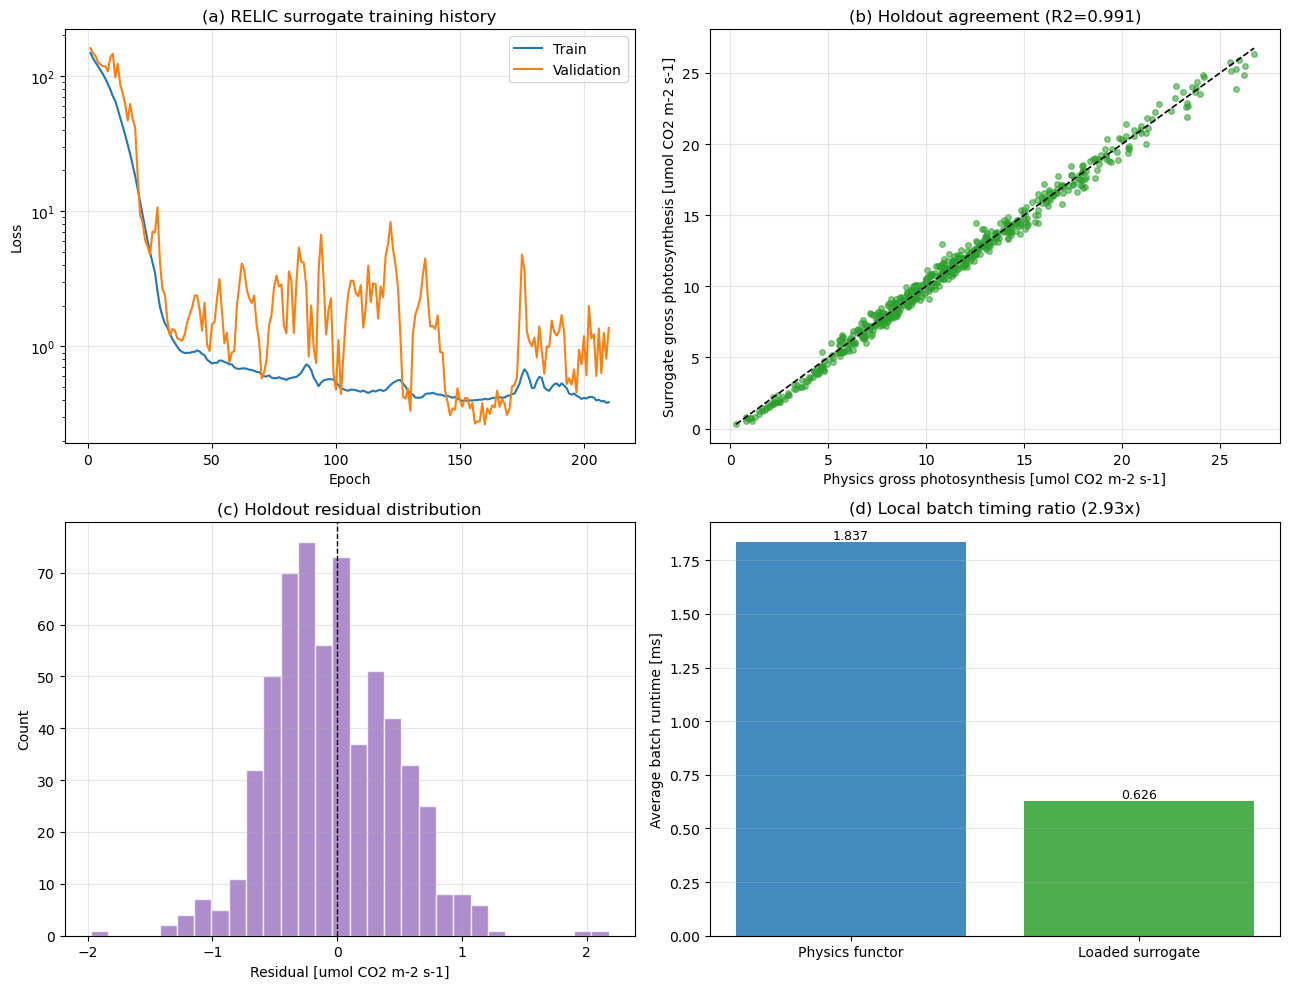

[OK] Surrogate diagnostics plot generated
  physics batch runtime:   1.837 ms
  surrogate batch runtime: 0.626 ms
  local timing ratio:      2.93x
  scope: single environment; do not generalize as a portable speedup claim


In [6]:
# References:
# 1. RELIC docs/source/theory/surrogates.md.
# 2. Farquhar et al. (1980), Planta 149:78-90.
# Mathematical expressions:
# 1. RMSE = sqrt(mean((y - y_hat)^2)).
# 2. speedup = t_physics / t_surrogate.
# Parameter meanings:
# 1. warmup_repeats: untimed calls used to stabilize cache and module state.
# 2. benchmark_repeats: timed calls used for the average batch runtime.
# 3. residual: surrogate minus physics holdout prediction error.
# Units:
# 1. Residuals use umol CO2 m-2 s-1; timings use milliseconds per batch.
# Domain/constraints:
# 1. The timing is a single-environment tutorial microbenchmark, not a portable performance claim.
# Sign convention:
# 1. Positive residual means the surrogate predicts more uptake than the physics functor.


def benchmark_functor(
    functor,
    state_batch: dict,
    benchmark_repeats: int = 80,
    warmup_repeats: int = 10,
    capture_diagnostics: bool = False,
) -> float:
    for _ in range(warmup_repeats):
        if capture_diagnostics:
            with warnings.catch_warnings(record=True):
                warnings.simplefilter("always")
                functor(state_batch, time=0.0, dt=dt_seconds)
        else:
            functor(state_batch, time=0.0, dt=dt_seconds)

    start = time.perf_counter()
    for _ in range(benchmark_repeats):
        if capture_diagnostics:
            with warnings.catch_warnings(record=True):
                warnings.simplefilter("always")
                functor(state_batch, time=0.0, dt=dt_seconds)
        else:
            functor(state_batch, time=0.0, dt=dt_seconds)
    end = time.perf_counter()
    return (end - start) * 1000.0 / float(benchmark_repeats)


train_loss_series = training_history["training_history"]["train_loss"]
val_loss_series = training_history["training_history"]["val_loss"]
residual_t = loaded_prediction_t - test_truth_t
physics_runtime_ms = benchmark_functor(
    physics_functor,
    test_state_batch,
    capture_diagnostics=True,
)
surrogate_runtime_ms = benchmark_functor(loaded_surrogate, test_state_batch)
speedup = physics_runtime_ms / surrogate_runtime_ms

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

ax = axes[0, 0]
ax.semilogy(
    range(1, len(train_loss_series) + 1),
    train_loss_series,
    label="Train",
    color="tab:blue",
)
ax.semilogy(
    range(1, len(val_loss_series) + 1),
    val_loss_series,
    label="Validation",
    color="tab:orange",
)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("(a) RELIC surrogate training history")
ax.grid(True, alpha=0.3)
ax.legend()

ax = axes[0, 1]
ax.scatter(
    test_truth_t.cpu().tolist(),
    loaded_prediction_t.cpu().tolist(),
    s=16,
    alpha=0.55,
    color="tab:green",
)
line_min = float(torch.min(test_truth_t).item())
line_max = float(torch.max(test_truth_t).item())
ax.plot([line_min, line_max], [line_min, line_max], "k--", linewidth=1.2)
ax.set_xlabel("Physics gross photosynthesis [umol CO2 m-2 s-1]")
ax.set_ylabel("Surrogate gross photosynthesis [umol CO2 m-2 s-1]")
ax.set_title(f"(b) Holdout agreement (R2={loaded_metrics['r2']:.3f})")
ax.grid(True, alpha=0.3)

ax = axes[1, 0]
ax.hist(
    residual_t.cpu().tolist(),
    bins=30,
    color="tab:purple",
    alpha=0.75,
    edgecolor="white",
)
ax.axvline(0.0, color="k", linestyle="--", linewidth=1.0)
ax.set_xlabel("Residual [umol CO2 m-2 s-1]")
ax.set_ylabel("Count")
ax.set_title("(c) Holdout residual distribution")
ax.grid(True, alpha=0.3)

ax = axes[1, 1]
bars = ax.bar(
    ["Physics functor", "Loaded surrogate"],
    [physics_runtime_ms, surrogate_runtime_ms],
    color=["#1f77b4", "#2ca02c"],
    alpha=0.85,
)
ax.set_ylabel("Average batch runtime [ms]")
ax.set_title(f"(d) Local batch timing ratio ({speedup:.2f}x)")
ax.grid(True, alpha=0.3, axis="y")
for bar, value in zip(bars, [physics_runtime_ms, surrogate_runtime_ms]):
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

print("[OK] Surrogate diagnostics plot generated")
print(f"  physics batch runtime:   {physics_runtime_ms:.3f} ms")
print(f"  surrogate batch runtime: {surrogate_runtime_ms:.3f} ms")
print(f"  local timing ratio:      {speedup:.2f}x")
print("  scope: single environment; do not generalize as a portable speedup claim")

In [7]:
# References:
# 1. Farquhar et al. (1980), Planta 149:78-90.
# 2. RELIC docs/source/theory/surrogates.md.
# Mathematical expressions:
# 1. error_abs = |y_phys - y_surrogate|.
# 2. forward contract: DeltaS = F(state, time, dt).
# Parameter meanings:
# 1. sample_idx: holdout state index.
# 2. y_phys: physics holdout prediction.
# 3. y_surrogate: loaded surrogate holdout prediction.
# Units:
# 1. Both predictions and the absolute error use umol CO2 m-2 s-1.
# Domain/constraints:
# 1. The selected sample must lie in the untouched holdout partition.
# Sign convention:
# 1. Positive gross photosynthesis denotes atmospheric CO2 uptake.

sample_idx = 0
single_state = build_training_state(
    X_test_t[sample_idx:sample_idx + 1, 0],
    X_test_t[sample_idx:sample_idx + 1, 1],
    X_test_t[sample_idx:sample_idx + 1, 2],
    X_test_t[sample_idx:sample_idx + 1, 3],
)

with warnings.catch_warnings(record=True) as single_state_diagnostics:
    warnings.simplefilter("always")
    physics_single = torch.as_tensor(
        unwrap_update(physics_functor(single_state, time=0.0, dt=dt_seconds)["gross_photosynthesis"]),
        dtype=torch.float32,
    ).reshape(-1)[0]

surrogate_single = torch.as_tensor(
    loaded_surrogate(single_state, time=0.0, dt=dt_seconds)["gross_photosynthesis"],
    dtype=torch.float32,
).reshape(-1)[0]

single_abs_error = float(torch.abs(physics_single - surrogate_single).item())

print("=== Single-State Functor Check ===")
print(f"  sample index:         {sample_idx}")
print(f"  physics gross photosynthesis:   {float(physics_single.item()):.6f}")
print(f"  surrogate gross photosynthesis: {float(surrogate_single.item()):.6f}")
print(f"  absolute error:       {single_abs_error:.6f}")
print(f"  captured diagnostics: {len(single_state_diagnostics)}")
for message in [str(item.message) for item in single_state_diagnostics]:
    print(f"    {message}")

=== Single-State Functor Check ===
  sample index:         0
  physics gross photosynthesis:   11.379068
  surrogate gross photosynthesis: 11.724315
  absolute error:       0.345246
  captured diagnostics: 0


## Summary

- Training data came from the real `FarquharPhotosynthesis` functor, with key
  biochemical parameters loaded from RELIC's parameter system.
- Model fitting, checkpointing, loss-history tracking, and physics-aware bounds
  all ran through `PyTorchSurrogate.train(...)`.
- Reloaded checkpoint predictions matched the trained surrogate on an untouched
  holdout set, so the reported accuracy is not inflated by post-load retraining.
- The resulting surrogate preserves the `FunctorBase` contract and can be swapped
  into larger RELIC workflows without notebook-side reimplementation of the
  scientific process.